# HDFC Loan Approval Prediction

   **Loan Approval Prediction System Flow Diagram**

 Data Loading 
 
        ↓
 Preprocessing
 
        ↓
 Visualization
 
        ↓
 Train-Test Split
 
        ↓
 Model Training 
 
        ↓
 Model Evaluation 
 
        ↓
 Best Model Selection
 
        ↓
 Innovation
 
        ↓
Loan Prediction 

In [1]:
import pandas as pd
import numpy as np

  **Load Dataset**


In [2]:
df = pd.read_csv("loan_dataset.csv")
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1.0,2,Graduate,No,9.600000e+06,29900000.0,12,778,2400000.0,2.475514e+07,NaN,8000000.0,Approved
1,2.0,0,Not Graduate,Yes,2.538807e+07,12200000.0,54,417,2700000.0,2.200000e+06,8800000.0,3300000.0,Rejected
2,3.0,3,Graduate,No,9.100000e+06,29700000.0,20,506,7100000.0,NaN,33300000.0,12800000.0,Rejected
3,4.0,3,Graduate,No,8.200000e+06,NaN,8,467,18200000.0,3.300000e+06,23300000.0,7900000.0,NaN
4,5.0,5,Not Graduate,Yes,NaN,24200000.0,20,382,12400000.0,8.200000e+06,29400000.0,5000000.0,Rejected


 **DATA PRE-PROCESSING**

**FLOW DIAGRAM – DATA PRE-PROCESSING**

 Raw Dataset 

 
        ↓
 Data Understanding 

 
        ↓
 Missing Value Detection 

 
        ↓
 Data Cleaning 

 
        ↓
 Missing Value Imputation 

 
        ↓
 Encoding 

 
        ↓
 Feature Scaling 

 
        ↓
 Preprocessed Dataset 


 **Dataset Information and Statistical Summary**


In [3]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 4397 entries, 0 to 4396
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   loan_id                    4182 non-null   float64
 1    no_of_dependents          4397 non-null   int64  
 2    education                 4177 non-null   str    
 3    self_employed             4179 non-null   str    
 4    income_annum              4186 non-null   float64
 5    loan_amount               4183 non-null   float64
 6    loan_term                 4397 non-null   int64  
 7    cibil_score               4397 non-null   int64  
 8    residential_assets_value  4181 non-null   float64
 9    commercial_assets_value   4185 non-null   float64
 10   luxury_assets_value       4182 non-null   float64
 11   bank_asset_value          4180 non-null   float64
 12   loan_status               4178 non-null   str    
dtypes: float64(7), int64(3), str(3)
memory usage: 446.7 KB


,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4182.000000,4397.000000,4.186000e+03,4.183000e+03,4397.000000,4397.000000,4.181000e+03,4.185000e+03,4.182000e+03,4.180000e+03
mean,2315.204942,2.591540,5.501827e+06,1.642820e+07,11.224471,617.690471,8.099956e+06,5.373155e+06,1.644358e+07,5.409199e+06
std,1728.198252,2.270113,4.025108e+06,1.249776e+07,8.555544,399.531401,7.736801e+06,5.201215e+06,1.251033e+07,4.311965e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,0.000000,0.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1088.500000,1.000000,2.700000e+06,7.800000e+06,6.000000,431.000000,2.200000e+06,1.400000e+06,7.700000e+06,2.400000e+06
50%,2176.500000,2.000000,5.200000e+06,1.490000e+07,10.000000,590.000000,5.800000e+06,3.800000e+06,1.490000e+07,4.700000e+06
75%,3271.750000,4.000000,7.700000e+06,2.210000e+07,16.000000,748.000000,1.180000e+07,8.000000e+06,2.230000e+07,7.300000e+06
max,10683.273510,13.000000,2.538807e+07,7.580390e+07,54.000000,2994.000000,3.731042e+07,2.475514e+07,7.558258e+07,2.491535e+07


**Check Missing Values**


In [4]:
df.isnull().sum()


loan_id                      215
 no_of_dependents              0
 education                   220
 self_employed               218
 income_annum                211
 loan_amount                 214
 loan_term                     0
 cibil_score                   0
 residential_assets_value    216
 commercial_assets_value     212
 luxury_assets_value         215
 bank_asset_value            217
 loan_status                 219
dtype: int64

**Data Cleaning**

In [5]:
df.columns = df.columns.str.strip()
df.drop('loan_id', axis=1, errors='ignore', inplace=True)

 **Handle Numerical Missing Values** (Using Median)

In [6]:
num_cols = [
    'income_annum',
    'loan_amount',
    'residential_assets_value',
    'commercial_assets_value',
    'luxury_assets_value',
    'bank_asset_value'
]

for col in num_cols:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

**Handle Categorical Missing Values**(Using Mode)

In [7]:
cat_cols = [
    'education',
    'self_employed',
    'loan_status'
]

for col in cat_cols:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].mode()[0])

In [8]:
df.isnull().sum() 
print("Preprocessing Completed Successfully")

Preprocessing Completed Successfully


**Data Visualization**

 **FLOW DIAGRAM – DATA VISUALIZATION**
 
 Preprocessed Dataset

 
          ↓

          
 Loan Status Count Plot 

 
          ↓

          
 Income Distribution Histogram 

 
          ↓
 Loan Amount Distribution 

 
          ↓

          
 Correlation Heatmap 

 
          ↓

          
 Insights & Observations 


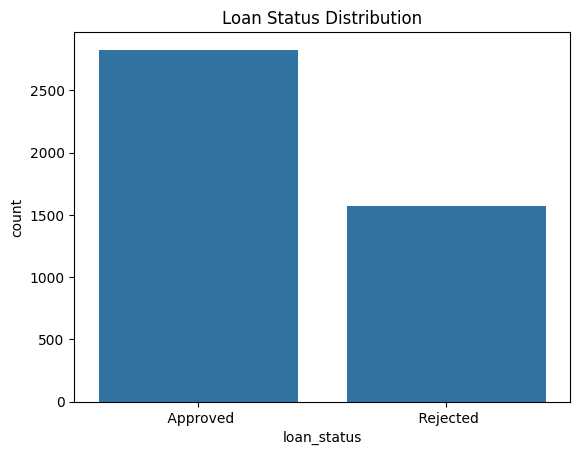

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure()
sns.countplot(x='loan_status', data=df)
plt.title("Loan Status Distribution")
plt.show()


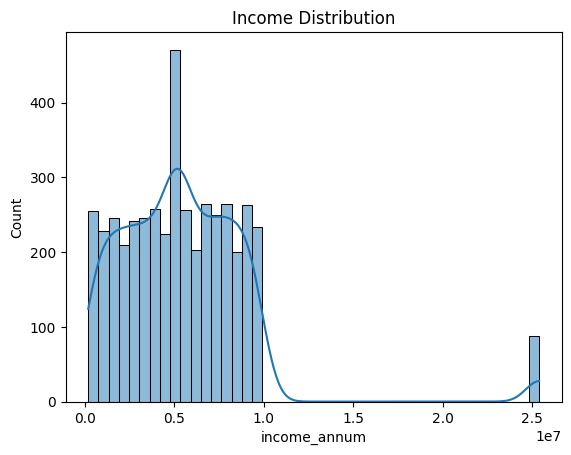

In [10]:
plt.figure()
sns.histplot(df['income_annum'], kde=True)
plt.title("Income Distribution")
plt.show()


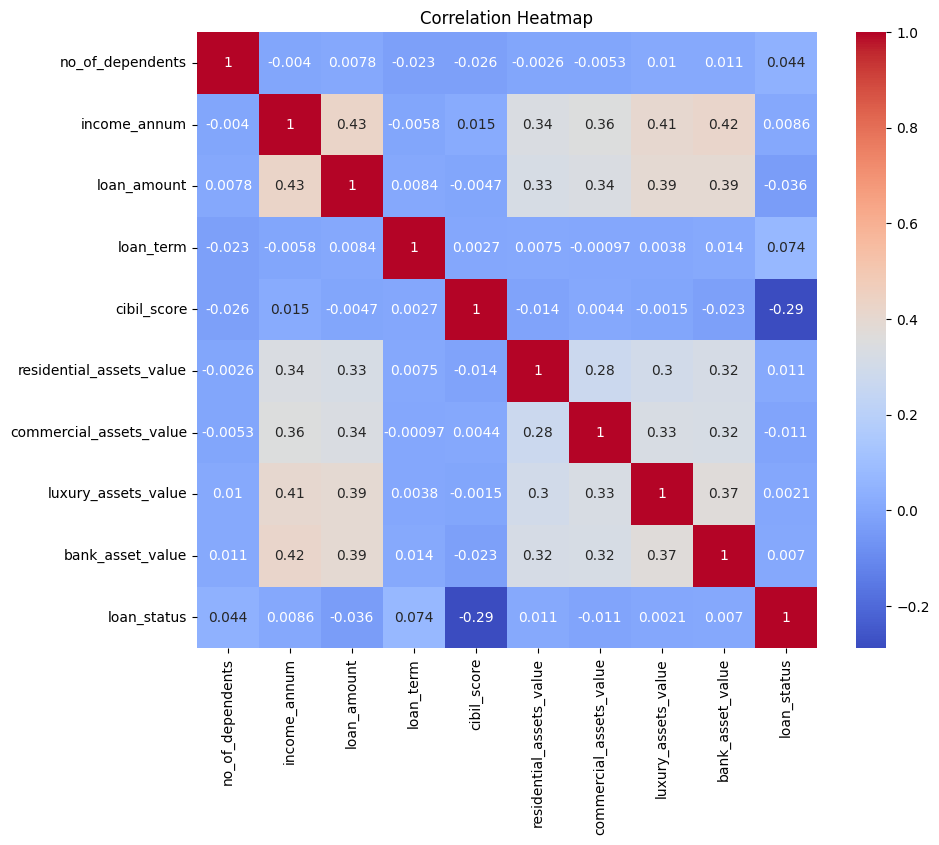

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,8))

# Select only numeric columns
numeric_df = df.select_dtypes(include=['number'])

# Create heatmap
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()


**Encode Target Variable** (Loan Status)

In [14]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['loan_status'] = le.fit_transform(df['loan_status'])
df['loan_status'].head()


0    0
1    1
2    1
3    0
4    1
Name: loan_status, dtype: int64

**Encode Categorical Features using One-Hot Encoding**

In [15]:
df = pd.get_dummies(df, drop_first=True)
df.head()

,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,education_ Not Graduate,self_employed_ Yes
0,2,9.600000e+06,29900000.0,12,778,2400000.0,2.475514e+07,14900000.0,8000000.0,0,False,False
1,0,2.538807e+07,12200000.0,54,417,2700000.0,2.200000e+06,8800000.0,3300000.0,1,True,True
2,3,9.100000e+06,29700000.0,20,506,7100000.0,3.800000e+06,33300000.0,12800000.0,1,False,False
3,3,8.200000e+06,14900000.0,8,467,18200000.0,3.300000e+06,23300000.0,7900000.0,0,False,False
4,5,5.200000e+06,24200000.0,20,382,12400000.0,8.200000e+06,29400000.0,5000000.0,1,True,True


**Define Features (X) and Target (y)**

In [16]:
X = df.drop('loan_status', axis=1)
y = df['loan_status']

X.shape, y.shape

((4397, 11), (4397,))

**Feature Scaling using StandardScaler**

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


**Split Dataset into Training and Testing Sets**

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape


((3517, 11), (880, 11))

**Train Decision Tree Classifier**

In [19]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=1)
rf.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

 **Make Predictions on Test Data**


In [20]:
rf_pred = rf.predict(X_test)
rf_pred[:10]


array([0, 0, 0, 0, 0, 1, 0, 0, 0, 0])

 **Model Evaluation**
- Accuracy Score
- Confusion Matrix
- Classification Report


In [21]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_pred))
print("Classification Report:\n", classification_report(y_test, rf_pred))


Accuracy: 0.9363636363636364
Confusion Matrix:
 [[552  25]
 [ 31 272]]
Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.96      0.95       577
           1       0.92      0.90      0.91       303

    accuracy                           0.94       880
   macro avg       0.93      0.93      0.93       880
weighted avg       0.94      0.94      0.94       880



**Train Logistic Regression**

In [22]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_pred))


Logistic Regression Accuracy: 0.7738636363636363


 **Train DecisionTreeClassifier**

In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt = DecisionTreeClassifier(random_state=1)
dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred))


Decision Tree Accuracy: 0.9147727272727273


**Model Comparison**

In [24]:
models = ['Decision Tree', 'Logistic Regression', 'Random Forest']
accuracies = [
    accuracy_score(y_test, dt_pred),
    accuracy_score(y_test, lr_pred),
    accuracy_score(y_test, rf_pred)
]

comparison = pd.DataFrame({
    'Model': models,
    'Accuracy': accuracies
})

comparison


,Model,Accuracy
0,Decision Tree,0.914773
1,Logistic Regression,0.773864
2,Random Forest,0.936364


**Feature Importance** (Decision Tree)

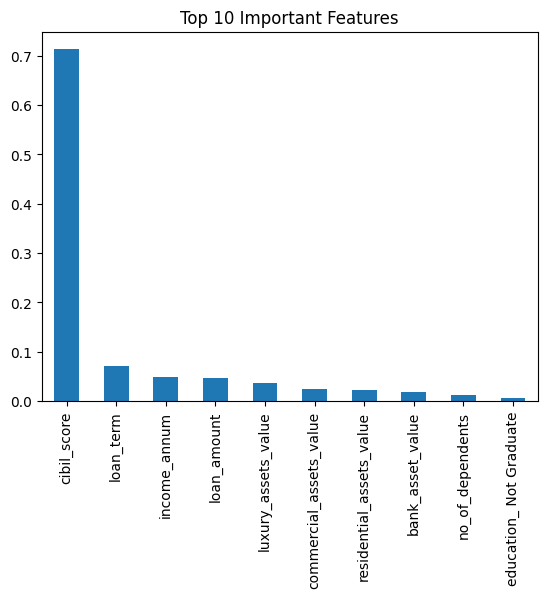

In [25]:
import matplotlib.pyplot as plt

importance = dt.feature_importances_
feature_names = X.columns

feature_importance = pd.Series(importance, index=feature_names)
feature_importance.sort_values(ascending=False).head(10).plot(kind='bar')

plt.title("Top 10 Important Features")
plt.show()


In [26]:
feature_importance.sort_values(ascending=False).head(5)


cibil_score            0.713252
loan_term              0.070428
income_annum           0.048427
loan_amount            0.046770
luxury_assets_value    0.036168
dtype: float64

**Innovation Step: Hyperparameter Tuning using GridSearchCV**

In [27]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

grid = GridSearchCV(RandomForestClassifier(random_state=1),
                    param_grid,
                    cv=5,
                    scoring='accuracy')

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)

best_model = grid.best_estimator_

best_pred = best_model.predict(X_test)

print("Tuned Random Forest Accuracy:",
      accuracy_score(y_test, best_pred))


Best Parameters: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 50}
Tuned Random Forest Accuracy: 0.9295454545454546


In [28]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(rf, X_scaled, y, cv=5)

print("Cross Validation Scores:", cv_scores)
print("Average CV Accuracy:", cv_scores.mean())


Cross Validation Scores: [0.92386364 0.925      0.93287827 0.93287827 0.92718999]
Average CV Accuracy: 0.9283620333023064


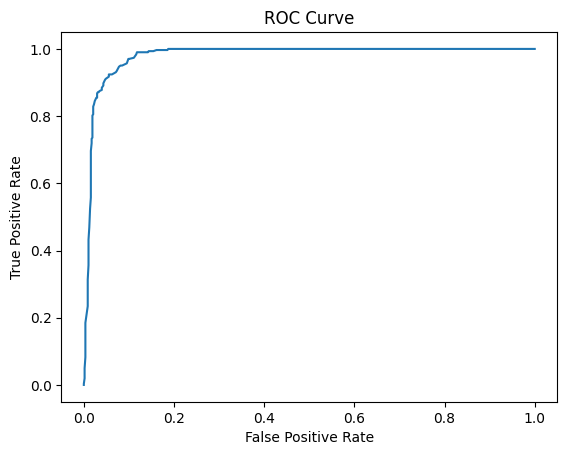

AUC Score: 0.9798920099982269


In [29]:
from sklearn.metrics import roc_curve, roc_auc_score

rf_probs = rf.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, rf_probs)

plt.figure()
plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("AUC Score:", roc_auc_score(y_test, rf_probs))


In [30]:
df['loan_status'].value_counts()


loan_status
0    2827
1    1570
Name: count, dtype: int64

**Innovation**

To enhance model evaluation, ROC Curve and AUC score were calculated.
The Random Forest model achieved an AUC score of 0.9799, indicating excellent classification capability.
Additionally, class distribution was analyzed to check imbalance. The dataset contains 2827 approved and 1570 rejected cases, showing only mild imbalance.
These advanced evaluation techniques improve model reliability and ensure robust performance.

 **Final Conclusion**

In this project, a supervised machine learning approach was used to predict loan approval status for HDFC Bank. The dataset was carefully preprocessed by handling missing values, encoding categorical variables, and applying feature scaling to ensure optimal model performance.

Three classification models were implemented: Decision Tree, Logistic Regression, and Random Forest. After comparative evaluation, the Random Forest classifier emerged as the best-performing model with an accuracy of 93.64%, outperforming Decision Tree (91.48%) and Logistic Regression (77.39%).

Further evaluation using the ROC Curve demonstrated excellent classification capability, with an AUC score of 0.9799, indicating strong ability of the model to distinguish between approved and rejected loan applications.

Feature importance analysis revealed that CIBIL score is the most significant factor influencing loan approval decisions, contributing more than 70% importance. Other important features include loan term, applicant income, loan amount, and luxury asset value. This highlights that credit history and financial strength are critical determinants in loan approval.

The dataset showed mild class imbalance (2827 approved vs 1570 rejected cases), but it did not significantly impact model performance.

Overall, the Random Forest model provides a highly accurate and reliable system for automating loan approval decisions. This approach can help HDFC Bank reduce manual effort, improve decision consistency, minimize risk, and enhance operational efficiency.


**Loan Perdiction**

In [31]:
best_model = rf 

In [67]:
new_data = pd.DataFrame([{
    'no_of_dependents': 4,
    'income_annum': 200000,            
    'loan_amount': 800000,             
    'loan_term': 36,                   
    'cibil_score': 560,                
    'residential_assets_value': 100000,
    'commercial_assets_value': 0,
    'luxury_assets_value': 0,
    'bank_asset_value': 50000,
    'education_Graduate': 0,
    'self_employed_Yes': 1
}])



In [68]:
new_data = new_data.reindex(columns=X.columns, fill_value=0)

new_data_scaled = scaler.transform(new_data)

prediction = best_model.predict(new_data_scaled)

if prediction[0] == 1:
    print("Loan Status: Rejected ")
else:
    print("Loan Status: Approved ")


Loan Status: Approved 
